# QSVM

Exemplo de kernel quântico para MNIST da apostila [Quantum Machine Learning: A Hands-on Tutorial for Machine Learning Practitioners and Researchers](https://qml-tutorial.github.io/code/kernel-mnist/).

In [1]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

## MNIST: dígitos 3 e 6

In [2]:
mnist = fetch_openml("mnist_784", version=1)


def load_mnist(n_qubit):
    X, y = mnist.data, mnist.target
    mask = (y == "3") | (y == "6")
    X_filtered = X[mask]
    y_filtered = np.where(y[mask] == "3", 0, 1)

    pca = PCA(n_components=n_qubit, random_state=42)
    X_reduced = pca.fit_transform(X_filtered)
    scaler = StandardScaler().fit(X_reduced)
    X_scaled = scaler.transform(X_reduced)

    return train_test_split(X_scaled, y_filtered, test_size=0.2, random_state=42)


n_qubit = 8
X_train, X_test, y_train, y_test = load_mnist(n_qubit)

## Amostra de treino: 100 imagens por dígito

In [3]:
n_sample_max = 100
X_train_sample = []
y_train_sample = []

for label in np.unique(y_train):
    index = y_train == label
    X_train_sample.append(X_train[index][:n_sample_max])
    y_train_sample.append(y_train[index][:n_sample_max])

X_train_sample = np.concatenate(X_train_sample, axis=0)
y_train_sample = np.concatenate(y_train_sample, axis=0)

print("Imagens de treino:", len(X_train_sample))
print("Imagens de teste:", len(X_test))

Imagens de treino: 200
Imagens de teste: 2804


## Exemplos dos dígitos

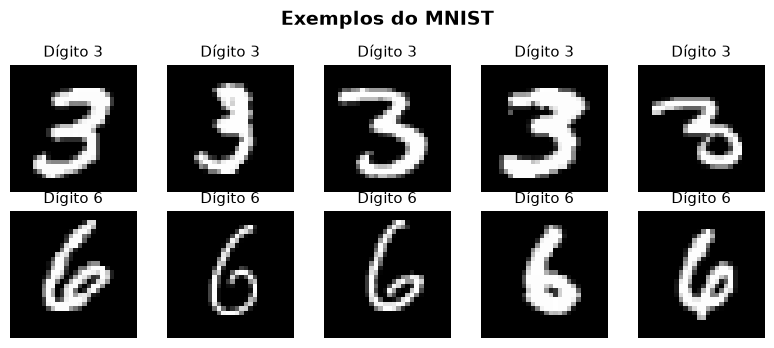

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))

for row, digit in enumerate(["3", "6"]):
    images = mnist.data[mnist.target == digit].iloc[:5].to_numpy()
    for axis, image in zip(axes[row], images):
        axis.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"Dígito {digit}", fontsize=11)
        axis.axis("off")

fig.suptitle("Exemplos do MNIST", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Visualização dos dados com t-SNE

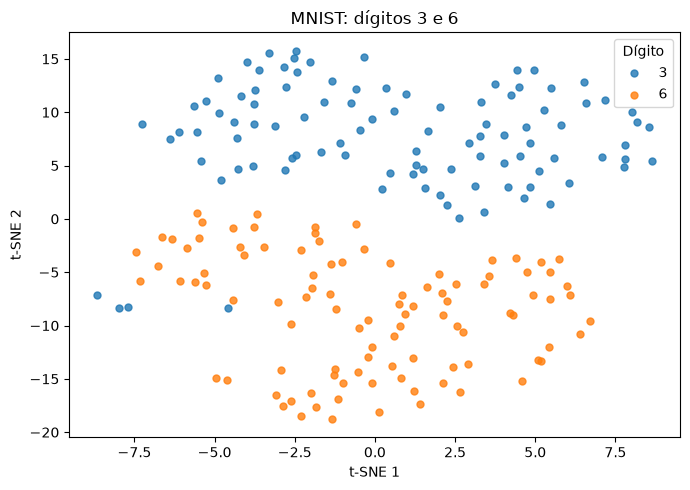

In [5]:
def visualize_dataset(X, labels):
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_tsne = tsne.fit_transform(X)
    label_names = {0: "3", 1: "6"}

    plt.figure(figsize=(7, 5))
    for label in np.unique(labels):
        indices = labels == label
        plt.scatter(X_tsne[indices, 0], X_tsne[indices, 1], s=25, alpha=0.8, label=label_names[label])

    plt.title("MNIST: dígitos 3 e 6")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend(title="Dígito")
    plt.tight_layout()
    plt.show()


visualize_dataset(X_train_sample, y_train_sample)

## Kernel quântico com AngleEmbedding

In [6]:
dev = qml.device("default.qubit", wires=n_qubit)


@qml.qnode(dev)
def kernel(x1, x2, n_qubit):
    qml.AngleEmbedding(x1, wires=range(n_qubit))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(n_qubit))
    return qml.expval(qml.Projector([0] * n_qubit, wires=range(n_qubit)))


def kernel_mat(A, B):
    return np.array([kernel(a, B, n_qubit) for a in A])

## Matriz do kernel

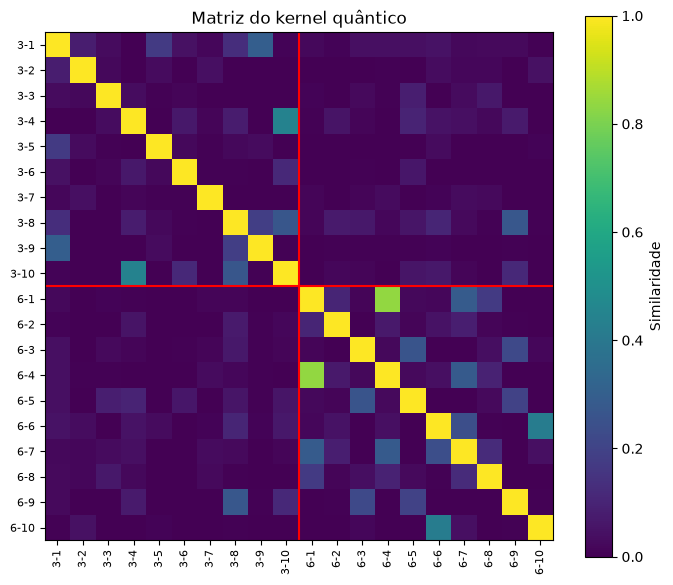

In [7]:
def visualize_kernel(X, y, n_sample):
    X_vis = np.concatenate([X[y == label][:n_sample] for label in np.unique(y)], axis=0)
    similarity = kernel_mat(X_vis, X_vis)
    labels = [f"3-{index + 1}" for index in range(n_sample)] + [f"6-{index + 1}" for index in range(n_sample)]

    plt.figure(figsize=(7, 6))
    plt.imshow(similarity, cmap="viridis", vmin=0, vmax=1)
    plt.colorbar(label="Similaridade")
    plt.axhline(n_sample - 0.5, color="red", linewidth=1.5)
    plt.axvline(n_sample - 0.5, color="red", linewidth=1.5)
    plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    plt.yticks(range(len(labels)), labels, fontsize=8)
    plt.title("Matriz do kernel quântico")
    plt.tight_layout()
    plt.show()


visualize_kernel(X_train_sample, y_train_sample, 10)

## Treinamento e avaliação do QSVM

In [8]:
kernel_mat_train = kernel_mat(X_train_sample, X_train_sample)
kernel_mat_test = kernel_mat(X_test, X_train_sample)
svm = SVC(kernel="precomputed")
accuracy = []
n_samples = []

for n_sample in range(10, n_sample_max + 10, 10):
    class1_indices = np.arange(n_sample)
    class2_indices = np.arange(n_sample_max, n_sample_max + n_sample)
    selected_indices = np.concatenate([class1_indices, class2_indices])

    svm.fit(kernel_mat_train[np.ix_(selected_indices, selected_indices)], y_train_sample[selected_indices])
    pred = svm.predict(kernel_mat_test[:, selected_indices])
    accuracy.append(accuracy_score(y_test, pred))
    n_samples.append(n_sample)

print(f"Acurácia: {accuracy_score(y_test, pred):.2%}")

Acurácia: 99.36%


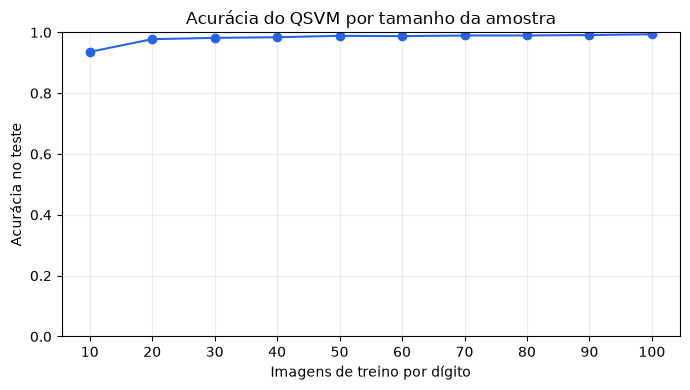

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(n_samples, accuracy, marker="o", color="#2563eb")
plt.title("Acurácia do QSVM por tamanho da amostra")
plt.xlabel("Imagens de treino por dígito")
plt.ylabel("Acurácia no teste")
plt.xticks(n_samples)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Matriz de confusão

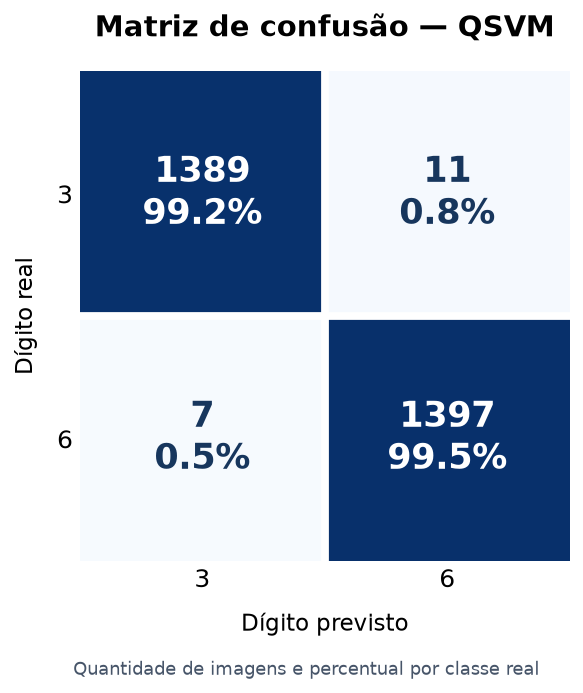

In [10]:
matrix = confusion_matrix(y_test, pred, labels=[0, 1])
percentages = matrix / matrix.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 5), dpi=140)
ax.imshow(matrix, cmap="Blues", vmin=0)

for row in range(2):
    for column in range(2):
        color = "white" if matrix[row, column] > matrix.max() / 2 else "#17365d"
        ax.text(column, row, f"{matrix[row, column]}\n{percentages[row, column]:.1%}", ha="center", va="center", fontsize=18, fontweight="bold", color=color)

ax.set_xticks([0, 1], ["3", "6"], fontsize=13)
ax.set_yticks([0, 1], ["3", "6"], fontsize=13)
ax.set_xlabel("Dígito previsto", fontsize=12, labelpad=10)
ax.set_ylabel("Dígito real", fontsize=12, labelpad=10)
ax.set_title("Matriz de confusão — QSVM", fontsize=15, fontweight="bold", pad=18)
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)
ax.grid(which="minor", color="white", linewidth=4)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(0.5, 0.025, "Quantidade de imagens e percentual por classe real", ha="center", fontsize=9, color="#475569")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()